## Business Problem

A global e-commerce company operating across multiple regions manages end-to-end order fulfillment, including shipping and delivery, for products like sporting goods. The company is facing inconsistent delivery performance, where actual shipping times often deviate from scheduled timelines, leading to late deliveries and unpredictable order profitability.

## Desired Outcome

The goal is to analyze delivery operations, identify bottlenecks, and build a predictive system to reduce delays, optimize shipping decisions, and improve overall profitability and efficiency.

In [205]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [206]:
df = pd.read_csv("D:/Supply_chain_dataset/DataCoSupplyChainDataset.csv",encoding='latin-1')

In [207]:
# Set professional color theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))
primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

In [208]:
#Overview
print("\nrows and columns",df.shape)
print("\ncolumns:")
print(df.columns.tolist())
print("\nnumber of Duplicates",df.duplicated().sum())
print("\nnull values",df.isna().sum())
print("\nnumber of missing values top (20)")
print(df.isna().sum().sort_values(ascending = False).head(10))


rows and columns (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', '

In [209]:
#droping uncessary columns
columns_to_drop = [
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Order Zipcode',
    'Longitude',
    'Latitude',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'Order Item Total',
    'Category Id',
    'Department Id',
    'Order Id',
    'Order Customer Id',
    'Customer Id',
    'Product Card Id',
    'Product Category Id',
    'Benefit per order',   # identical to Order Profit Per Order
    'Product Status',      # has only one value
    'Customer City',
    'Order City',
    'Order Country',
    'Order State',
    'Customer State',
    'Market'
]
# dropping columns that are either fully missing, redundant, or have only one value (and thus no variance)
df = df.drop(columns=columns_to_drop)

print(df['Delivery Status'].value_counts())

# removing canceled orders since they are not relevant for delivery time analysis and may have different patterns than completed orders
df = df[df['Delivery Status'] != 'Shipping canceled']

# Standard date conversion
for c in ["order date (DateOrders)","shipping date (DateOrders)"]:
    df[c] = pd.to_datetime(df[c],errors='coerce',dayfirst= False)

# after data cleaning, let's check the overview again to see how the dataset has changed
print("\nrows and columns ",df.shape)
print("\nnumber of missing values top (5)")
print(df.isna().sum().sort_values(ascending = False).head(5))

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

rows and columns  (172765, 20)

number of missing values top (5)
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


In [210]:
# value count for categorical columns with low cardinality
for col in df.columns:
    if df[col].nunique() < 10:
        print(f"\n{col} value_counts\n")
        print(df[col].value_counts())


Type value_counts

Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real) value_counts

Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled) value_counts

Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status value_counts

Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk value_counts

Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country value_counts

Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment value_counts

Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Status value_counts

Order Status
COMPLETE  

In [211]:
#calculating order processing time & delay
df['Order Processing Time'] = (df['shipping date (DateOrders)']-df['order date (DateOrders)']).dt.days
df['Delay'] = df['Order Processing Time']-df['Days for shipment (scheduled)']
df['Is_Delayed'] = df['Delay']>0
df['Order Month'] = df['order date (DateOrders)'].dt.month
df['Order Day'] = df['order date (DateOrders)'].dt.day_name()
df['Order Hour'] = df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,Order Month,Order Hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276


In [213]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [214]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'Order Month', 'Order Day', 'Order Hour'],
      dtype='str')

In [216]:
df['Profitability Flag'] = np.where(df['Order Profit Per Order']>0,'Profit',np.where(df['Order Profit Per Order']<0 ,'Loss','Break Even'))

In [224]:
df['Profitability Flag'].value_counts()

Profitability Flag
Profit        80.661014
Loss          18.693022
Break Even     0.645964
Name: proportion, dtype: float64

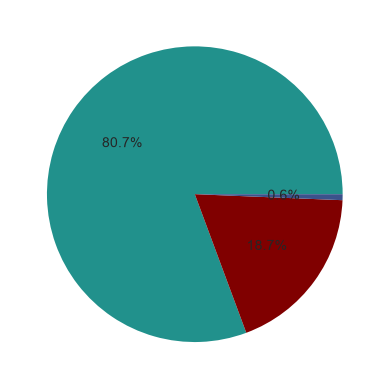

In [222]:
profit_counts = df['Profitability Flag'].value_counts(normalize=True)*100
plt.pie(profit_counts,autopct='%1.1f%%',colors=[accent_color,danger_color,secondary_color])
plt.show()

In [264]:
def format_func(value):
    if value >= 1e6:
        return f"{value/1e6:.1f}M $"
    elif value >= 1e3:
        return f"{value/1e3:.1f}K $"
    else:
        return f"{value:.0f} $"
        
delay_df = df[df['Delay']>0]
metrics ={}
metrics['Total Orders']= len(df)
metrics['Late_Deliveries'] = len(delay_df)
metrics['90% Delay(days)'] = delay_df['Delay'].quantile(0.90)
metrics['On Time Delivery %'] = (1 - float(metrics['Late_Deliveries'])/ metrics['Total Orders'])*100
metrics['Late Delivery %'] = float(metrics['Late_Deliveries'])/ metrics['Total Orders']

print("\n-------Bussiness KPI--------")
for k,v in metrics.items():
    if isinstance(v,float):
        print(f"{k} : {v:.2f}")
    else:
        print(f"{k} : {v}")


-------Bussiness KPI--------
Total Orders : 172765
Late_Deliveries : 94523
90% Delay(days) : 3.00
On Time Delivery % : 45.29
Late Delivery % : 0.55


{'Total Orders': 172765,
 'Late_Deliveries': 94523,
 '90% Delay(days)': np.float64(3.0),
 'On Time Delivery %': 45.28810812375191,
 'Late Delivery %': 0.5471189187624809,
 'Total Profit': '7.5M $'}

0.5471189187624809

In [258]:
metrics['Total Profit']= format_func(df.loc[df['Order Profit Per Order']>0,'Order Profit Per Order'].sum())

np.float64(7514813.809694838)